# Módulo 8 — Transformada de Fourier
## Seção 8.7 — Transformada Rápida de Fourier (FFT)

**Objetivo de aprendizagem.** Entender *por que* a FFT calcula a mesma DFT com menos operações, demonstrar a decomposição par–ímpar do algoritmo radix-2, implementá-lo em pequena escala e interpretar corretamente suas saídas em Python.

**Pré-requisitos:** Seções 8.3 (Euler), 8.4 (ortogonalidade), 8.6 (DFT); somas finitas, números complexos e noções elementares de recursão.

**Fonte principal consultada:** Morettin e Toloi (2018), *Análise de Séries Temporais: Modelos Lineares Univariados*, v. 1, cap. 13, §13.4, pp. 348–350, e cap. 14, §14.4.1, p. 367, eqs. (14.18)–(14.19), para a transformada finita e frequências de Fourier. **Complementação didática:** a decomposição radix-2 de Cooley–Tukey, o cálculo de complexidade e as APIs de NumPy não são desenvolvidos nessas páginas; não são apresentados como demonstrações atribuídas ao livro.

---

### 1. Por que precisamos de um algoritmo rápido?

A DFT de uma sequência finita $x_0,\ldots,x_{N-1}$, na convenção do NumPy adotada na Seção 8.6, é

$$X_k=\sum_{n=0}^{N-1}x_n\exp\!\left(-\frac{2\pi i kn}{N}\right),\qquad k=0,\ldots,N-1.$$

O cálculo direto exige $N$ somas com $N$ termos, isto é, aproximadamente $N^2$ contribuições complexas. **A FFT não modifica os coeficientes matemáticos da DFT**: ela reorganiza o cálculo para reutilizar resultados parciais. No caso radix-2, o custo cresce como $N\log_2N$.

Exemplo ilustrativo: para $N=1024$, a contagem idealizada de termos da DFT direta é $1024^2=1\,048\,576$; a quantidade $N\log_2N$ vale $10\,240$. Esses números ilustram *ordens de crescimento*, não um tempo real de execução ou contagem exata de operações.

### 2. O fator rotacional (twiddle factor)

Defina

$$W_N=\exp\!\left(-\frac{2\pi i}{N}\right).$$

Pela fórmula de Euler, $W_N^m=\cos(2\pi m/N)-i\sin(2\pi m/N)$. Sua propriedade essencial para $N$ par é

$$W_N^{2m}=\exp\!\left(-\frac{2\pi i m}{N/2}\right)=W_{N/2}^m.$$

É ela que permite aproveitar transformadas menores dentro da transformada original.

### 3. Demonstração passo a passo: separar índices pares e ímpares

Suponha inicialmente $N=2M$ e escreva o índice temporal como $n=2r$ ou $n=2r+1$, com $r=0,\ldots,M-1$. Então

$$\begin{aligned}
X_k&=\sum_{n=0}^{N-1}x_nW_N^{kn}\\
&=\sum_{r=0}^{M-1}x_{2r}W_N^{2kr}+\sum_{r=0}^{M-1}x_{2r+1}W_N^{k(2r+1)}\\
&=\underbrace{\sum_{r=0}^{M-1}x_{2r}W_M^{kr}}_{E_k}+W_N^k\underbrace{\sum_{r=0}^{M-1}x_{2r+1}W_M^{kr}}_{O_k}.
\end{aligned}$$

Portanto,

$$\boxed{X_k=E_k+W_N^kO_k,\qquad 0\leq k<M.}$$

Como $E_{k+M}=E_k$ e $O_{k+M}=O_k$ (periodicidade de uma DFT de comprimento $M$), enquanto $W_N^{k+M}=-W_N^k$, obtemos simultaneamente a segunda metade:

$$\boxed{X_{k+M}=E_k-W_N^kO_k,\qquad 0\leq k<M.}$$

Essas duas fórmulas formam a operação chamada **borboleta**: duas subtransformadas de tamanho $M$ geram todos os $N$ coeficientes, reutilizando $E_k$ e $O_k$.

**Hipótese da recursão radix-2:** dividir continuamente em partes iguais requer $N=2^m$. Há outros algoritmos de FFT para comprimentos diferentes; `numpy.fft.fft` também aceita tamanhos não potências de 2.

### 4. Exemplo calculado à mão para quatro observações

Considere $x=(1,2,0,-1)$ e $N=4$.

- Índices pares: $(x_0,x_2)=(1,0)$, portanto $E=(1,1)$.
- Índices ímpares: $(x_1,x_3)=(2,-1)$, portanto $O=(1,3)$.
- Fatores: $W_4^0=1$ e $W_4^1=-i$.

Aplicando a borboleta:

$$X_0=1+1=2,\quad X_1=1-3i,\quad X_2=1-1=0,\quad X_3=1+3i.$$

O resultado coincide exatamente com a DFT direta calculada na Seção 8.6.

In [1]:
import numpy as np
x = np.array([1., 2., 0., -1.])
pares = np.fft.fft(x[::2])
impares = np.fft.fft(x[1::2])
W = np.exp(-2j*np.pi*np.arange(2)/4)
X_borboleta = np.r_[pares+W*impares, pares-W*impares]
X_numpy = np.fft.fft(x)
print('Pares:', pares, '| Ímpares:', impares)
print('Borboleta:', X_borboleta)
print('NumPy:', X_numpy)
assert np.allclose(X_borboleta, [2, 1-3j, 0, 1+3j])
assert np.allclose(X_borboleta, X_numpy)

Pares: [1.+0.j 1.+0.j] | Ímpares: [1.+0.j 3.+0.j]
Borboleta: [2.+0.j 1.-3.j 0.+0.j 1.+3.j]
NumPy: [2.+0.j 1.-3.j 0.+0.j 1.+3.j]


**Interpretação:** `x[::2]` seleciona índices pares, `x[1::2]` seleciona ímpares; `np.r_` concatena as duas metades da transformada. Essa implementação usa FFT apenas nas duas subtransformadas para facilitar a inspeção; na próxima célula construiremos a recursão manualmente.

### 5. Implementação didática completa (não otimizada)

Antes de consultar a biblioteca, construímos nosso próprio procedimento. A função abaixo aceita apenas potências de dois, faz chamadas recursivas e combina as metades pela borboleta. Ela serve para estudar o algoritmo — uma implementação Python recursiva não costuma ser competitiva com a versão compilada do NumPy.

In [2]:
def fft_radix2(x):
    x = np.asarray(x, dtype=complex)
    N = x.size
    if N == 1:
        return x.copy()
    if N == 0 or (N & (N - 1)) != 0:
        raise ValueError('Esta versão didática exige N = 2^m e N >= 1.')
    E = fft_radix2(x[::2])
    O = fft_radix2(x[1::2])
    W = np.exp(-2j*np.pi*np.arange(N//2)/N)
    return np.concatenate((E+W*O, E-W*O))

rng = np.random.default_rng(2026)
for N in [2, 4, 8, 16, 64]:
    amostra = rng.normal(size=N)
    assert np.allclose(fft_radix2(amostra), np.fft.fft(amostra), atol=1e-11)
print('FFT radix-2 confere com numpy.fft.fft para N = 2, 4, 8, 16 e 64.')

FFT radix-2 confere com numpy.fft.fft para N = 2, 4, 8, 16 e 64.


### 6. Prova da ordem de complexidade

Se $T(N)$ representa o número de operações para transformar $N=2^m$ observações, a separação par–ímpar requer duas transformadas de tamanho $N/2$ e uma combinação de custo proporcional a $N$:

$$T(N)=2T(N/2)+cN,\qquad T(1)=O(1).$$

Após $m$ expansões, $T(N)=2^mT(1)+mcN$. Como $2^m=N$ e $m=\log_2N$,

$$\boxed{T(N)=O(N\log_2N).}$$

A prova vale para a estratégia radix-2 descrita. O custo de memória e detalhes de implementação podem alterar desempenho prático sem invalidar a ordem assintótica.

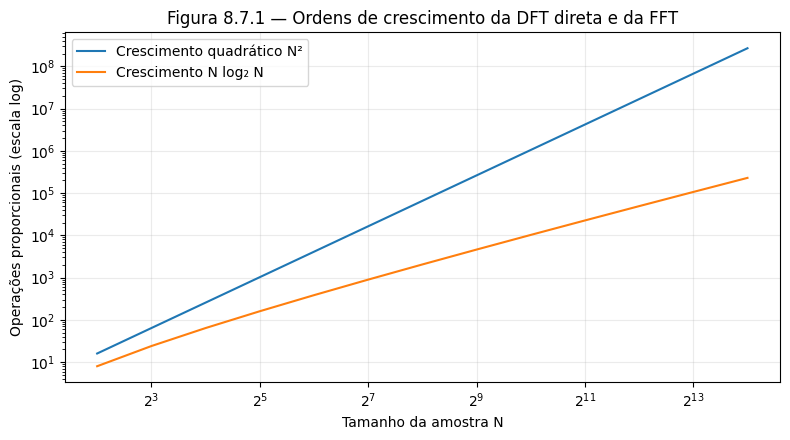

In [3]:
import matplotlib.pyplot as plt
Ns = 2**np.arange(2, 15)
plt.figure(figsize=(8, 4.5))
plt.plot(Ns, Ns**2, label='Crescimento quadrático N²')
plt.plot(Ns, Ns*np.log2(Ns), label='Crescimento N log₂ N')
plt.xscale('log', base=2)
plt.yscale('log')
plt.xlabel('Tamanho da amostra N')
plt.ylabel('Operações proporcionais (escala log)')
plt.title('Figura 8.7.1 — Ordens de crescimento da DFT direta e da FFT')
plt.legend(); plt.grid(alpha=.25); plt.tight_layout(); plt.show()

**Interpretação da Figura 8.7.1:** a distância entre as curvas aumenta à medida que o tamanho cresce; trata-se de uma comparação *teórica de ordens de crescimento*, não de tempos cronometrados.

### 7. Da FFT aos coeficientes físicos

Para uma série real amostrada com intervalo $\Delta t$, `np.fft.rfft(x)` retorna apenas as frequências não negativas, e `np.fft.rfftfreq(N, d=dt)` indica sua escala física em ciclos por unidade de tempo. Para uma senoide de frequência exatamente sobre a grade da DFT, sem termo de média, a amplitude é $2|X_k|/N$ nos bins internos positivos; o fator 2 **não** é usado em DC ($k=0$), nem no bin de Nyquist quando $N$ é par.

Frequência recuperada = 0.500; amplitude recuperada = 3.000


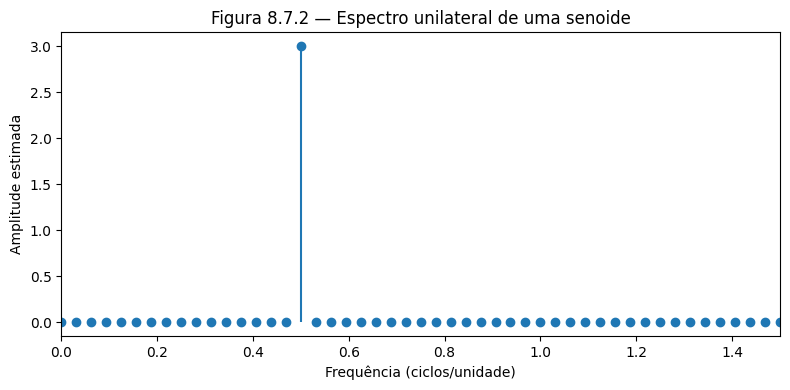

In [4]:
N, dt, A, f0 = 128, 0.25, 3.0, 0.5  # 4 amostras por unidade; 0.5 ciclos/unidade
t = np.arange(N)*dt
x = A*np.cos(2*np.pi*f0*t + 0.4)
f = np.fft.rfftfreq(N, d=dt)
X = np.fft.rfft(x)
amplitude = np.abs(X)/N
amplitude[1:-1] *= 2  # N é par; último bin representa Nyquist
k = np.argmax(amplitude[1:])+1
print(f'Frequência recuperada = {f[k]:.3f}; amplitude recuperada = {amplitude[k]:.3f}')
assert np.isclose(f[k], f0)
assert np.isclose(amplitude[k], A)
plt.figure(figsize=(8, 4))
plt.stem(f, amplitude, basefmt=' ')
plt.xlim(0, 1.5); plt.xlabel('Frequência (ciclos/unidade)')
plt.ylabel('Amplitude estimada'); plt.title('Figura 8.7.2 — Espectro unilateral de uma senoide')
plt.tight_layout(); plt.show()

**Interpretação da Figura 8.7.2:** o pico em $0{,}5$ ciclos/unidade representa a frequência da senoide simulada. A leitura direta de uma amplitude exige atenção à normalização, à posição do bin, à janela e ao eventual vazamento espectral.

### 8. Cuidados metodológicos

A FFT não pressupõe que o processo gerador seja estacionário, mas **interpretar seus coeficientes como estimativas estáveis do conteúdo espectral de um processo** exige hipóteses adicionais, desenvolvidas no Módulo 9. Outros cuidados: tendência ou média podem dominar bins de baixa frequência; frequências fora da grade produzem vazamento; adicionar zeros (*zero-padding*) interpola a visualização da DFT, sem criar nova informação temporal; observações irregulares não devem ser passadas à FFT como se estivessem igualmente espaçadas.

### 9. Exercícios orientados

1. **Pseudocódigo:** escreva, sem Python, os passos para calcular uma FFT radix-2 de 8 pontos e marque as chamadas recursivas.
2. **Prova:** verifique explicitamente a identidade $W_N^{k+N/2}=-W_N^k$.
3. **Investigação:** compare `fft_radix2` com `np.fft.fft` para $N=256$, sem extrapolar um único cronômetro para uma lei de complexidade.
4. **Interpretação:** simule uma senoide fora da grade e descreva a distribuição de suas amplitudes entre bins.
5. **Desafio:** explique por que *zero-padding* não melhora a resolução física $1/(N\Delta t)$ da janela observada.

**Síntese.** A DFT define os coeficientes; a FFT é um algoritmo eficiente para calculá-los. O significado físico dos coeficientes depende do intervalo de amostragem, do comprimento da janela e das hipóteses estatísticas.